Class Grade Distribution Analysis in Jupyter Notebook using Python, NumPy, and Matplot   
Isabella Morgan  
CYBI-4336-01  

This notebook will analyze a class grade dataset stored in an Excel workbook (csv file). The dataset contains the grades for 20 students of ten graded activities, consisting of:
    - five quizzes
    - three labs
    - two exams
The purpose of this lab is to load the grades into a NumPy 2-D array, calculate averages for every assignment and every student, and use two graph to visually compare the students' performance in their quizzes, labs, and exams.

Import Libraries:
NumPy: numerical work
Matplotlib: graphs
openpyxl: read the Excel workbook

In [35]:
import numpy as np
import matplotlib.pyplot as plt
from openpyxl import load_workbook

Task 1: Examine the excel file
The next cell open the Excel sheet for the grades and reads only the heading row and the Student ID colum, so we can confirm the layout. It will count the student records and the quiz, lab, and exams columns without writing to the workbook.
•  How many student records are present?
    - 20 students
•  How many quiz, lab, and exam columns are present?
    - 10 columns broken down into 5 quiz, 3 lab, and 2 exam columns
•  What are the lowest and highest possible grades?
    - lowest: 58, highest: 100

In [36]:
#open notebook, read only
wb = load_workbook(filename='Class Grade Distribution.xlsx', data_only=True, read_only=True)
#output the worksheets & select the one titled "Grades"
print('Worksheets:', wb.sheetnames)
ws = wb['Grades']

#read every row as a tuple
all_rows = list(ws.iter_rows(values_only=True))

#1st row = column headings, starts @ index 0
headings = all_rows[0]
print('Headings:', headings)

#the 1st heading should be student id, the following ten are graded activities
print('First column is Student ID:', headings[0] == 'Student ID')
assignment_names = list(headings[1:11])

#every row agter the heading row is a studeent record
#the end of the index range isnt hard coded in in case this script could be used for a larger dataset
records = all_rows[1:]
print('Student records:', len(records))

#count the columns in each ctegory
print('Quiz columns:', sum(name.startswith('Quiz') for name in assignment_names))
print('Lab columns: ', sum(name.startswith('Lab') for name in assignment_names))
print('Exam columns:', sum(name.startswith('Exam') for name in assignment_names))

#close workbook
wb.close()

Worksheets: ['Grades']
Headings: ('Student ID', 'Quiz 1', 'Quiz 2', 'Quiz 3', 'Quiz 4', 'Quiz 5', 'Lab 1', 'Lab 2', 'Lab 3', 'Exam 1', 'Exam 2')
First column is Student ID: True
Student records: 20
Quiz columns: 5
Lab columns:  3
Exam columns: 2


Task 2: Reading the Excel File
This code cell opens the Grades workbook and copies its numeric values into a Numpy array. Student IDs cant be ingested since they are text, so they'll go into a separate list.

In [37]:
#open Excel workbook in read-only mode
workbook = load_workbook(
    filename='Class Grade Distribution.xlsx',
    data_only=True,
    read_only=True
)

# grab workbook named Grades
sheet = workbook['Grades']

# empty arrays for list for labels and another for numeric grade rows
student_ids = []
grade_rows = []

# skip row 1 because it contains column headings. load in data
for row in sheet.iter_rows(min_row=2, max_col=11, values_only=True):
    student_ids.append(row[0])       # First value is the Student ID.
    grade_rows.append(row[1:11])     # Next ten values are numeric grades.

# convert the list of grade rows into a NumPy 2-D array
grades = np.array(grade_rows, dtype=float)

# close workbook
workbook.close()

# check the contents and structure of the new array
print(grades)
print('Shape:', grades.shape)
print('Dimensions:', grades.ndim)
print('Data type:', grades.dtype)

[[ 88.  92.  84.  90.  86.  94.  91.  89.  87.  90.]
 [ 76.  81.  79.  74.  83.  85.  82.  88.  78.  81.]
 [ 95.  93.  97.  91.  96.  98.  94.  97.  92.  95.]
 [ 68.  72.  75.  70.  66.  79.  74.  77.  69.  73.]
 [ 84.  87.  82.  89.  85.  90.  88.  92.  86.  89.]
 [ 91.  86.  89.  93.  90.  87.  91.  90.  88.  92.]
 [ 73.  78.  71.  80.  76.  82.  79.  84.  75.  77.]
 [ 99.  96.  98.  97.  95. 100.  98.  96.  94.  98.]
 [ 62.  69.  65.  71.  67.  73.  70.  75.  64.  68.]
 [ 87.  85.  90.  88.  92.  93.  89.  91.  90.  87.]
 [ 79.  83.  77.  81.  80.  86.  84.  82.  76.  83.]
 [ 93.  89.  94.  92.  90.  95.  93.  96.  91.  94.]
 [ 71.  74.  69.  77.  73.  80.  76.  78.  72.  75.]
 [ 85.  91.  88.  86.  89.  92.  90.  87.  84.  88.]
 [ 58.  64.  61.  67.  63.  70.  68.  72.  60.  65.]
 [ 82.  79.  85.  83.  81.  88.  86.  84.  80.  85.]
 [ 96.  94.  92.  98.  93.  97.  95.  99.  93.  96.]
 [ 77.  75.  82.  78.  80.  83.  81.  85.  79.  82.]
 [ 89.  88.  86.  91.  87.  90.  94.  92.  85.

Task 3: Inspect the NumPy Array

The next cell uses indexing and slicing to look at parts of the array: the first and last student rows, the quiz grades for Student S05, and the Exam 2 column. It finishes by checking that every grade lies between 0 and 100.

In [38]:
# index 0 = 1st student row & index -1 = last student row
print('First student row ('+ student_ids[0] +'):', grades[0])
print('Last student row  ('+ student_ids[-1] +'):', grades[-1])

# find the row number for S05, then slice columns 0-4 (the five quizzes)
s05_row = student_ids.index('S05')
print('S05 quiz grades:', grades[s05_row, 0:5])

# seelct every row of the last column to get all exam 2 grades
print('Exam 2 grades:', grades[:, -1])

# use np max and min to confirm all values are between 0 and 100
print('Minimum grade:', np.min(grades))
print('Maximum grade:', np.max(grades))
print('All values between 0 and 100:', np.min(grades) >= 0 and np.max(grades) <= 100)

First student row (S01): [88. 92. 84. 90. 86. 94. 91. 89. 87. 90.]
Last student row  (S20): [66. 70. 68. 72. 74. 76. 73. 79. 67. 71.]
S05 quiz grades: [84. 87. 82. 89. 85.]
Exam 2 grades: [90. 81. 95. 73. 89. 92. 77. 98. 68. 87. 83. 94. 75. 88. 65. 85. 96. 82.
 91. 71.]
Minimum grade: 58.0
Maximum grade: 100.0
All values between 0 and 100: True


Task 4: Calculate Column and Row Averages
Using np.mean() with axis=0 to get one avg. per assignmend and then using axis=1 to get one average per atudent. Then it will print each assignment name beside its column average, and print each Student ID beside the student’s row average.


In [39]:
# axis=0 averages down each column giving one value per assignment
column_averages = np.mean(grades, axis=0)
# axis=1 averages across each row
#this will return one value per student
student_averages = np.mean(grades, axis=1)

# print the two result arrays rounded to two decimal places
print('Column averages:', np.round(column_averages, 2))
print('Student averages:', np.round(student_averages, 2))

# output each assignment name beside its column average
print('\nAverage by assignment:')
for name, avg in zip(assignment_names, column_averages):
    print(f'{name:<8} {avg:6.2f}')

# output each Student ID next to that student's row average
print('\nCumulative average by student:')
for sid, avg in zip(student_ids, student_averages):
    print(f'{sid:<8} {avg:6.2f}')

Column averages: [80.95 82.3  81.6  83.4  82.3  86.9  84.8  86.65 80.5  84.  ]
Student averages: [89.1 80.7 94.8 72.3 87.2 89.7 77.5 97.1 68.4 89.2 81.1 92.7 74.5 88.
 64.8 83.3 95.3 80.2 89.3 71.6]

Average by assignment:
Quiz 1    80.95
Quiz 2    82.30
Quiz 3    81.60
Quiz 4    83.40
Quiz 5    82.30
Lab 1     86.90
Lab 2     84.80
Lab 3     86.65
Exam 1    80.50
Exam 2    84.00

Cumulative average by student:
S01       89.10
S02       80.70
S03       94.80
S04       72.30
S05       87.20
S06       89.70
S07       77.50
S08       97.10
S09       68.40
S10       89.20
S11       81.10
S12       92.70
S13       74.50
S14       88.00
S15       64.80
S16       83.30
S17       95.30
S18       80.20
S19       89.30
S20       71.60


Task 5: Calculate Category Averages per Student
Now, we'll slice the array into quiz, lab, and exam columns and averages each slice across every row. The corresponding student will be printed by their averages.

In [44]:
# quiz: 0-4, lab: 5-7, and exam :8-9
# axis=1 averages across the columns of each slice thus one result per student
quiz_averages = np.mean(grades[:, 0:5], axis=1)
lab_averages = np.mean(grades[:, 5:8], axis=1)
exam_averages = np.mean(grades[:, 8:10], axis=1)

# output a table heading and a divider line
print(f"{'Student: |':<9}{' Quiz Avg: |':>10}{' Lab Avg: |':>10}{' Exam Avg: |':>10}{' Overall Avg: |':>13}")
print('-' * 60)

# print one formatted line per student, reusing student_averages from task4
for i, sid in enumerate(student_ids):
    print(f'{sid:<9}{quiz_averages[i]:>10.2f}{lab_averages[i]:>10.2f}'
          f'{exam_averages[i]:>10.2f}{student_averages[i]:>13.2f}')
    print('-' * 60)


Student: | Quiz Avg: | Lab Avg: | Exam Avg: | Overall Avg: |
------------------------------------------------------------
S01           88.00     91.33     88.50        89.10
------------------------------------------------------------
S02           78.60     85.00     79.50        80.70
------------------------------------------------------------
S03           94.40     96.33     93.50        94.80
------------------------------------------------------------
S04           70.20     76.67     71.00        72.30
------------------------------------------------------------
S05           85.40     90.00     87.50        87.20
------------------------------------------------------------
S06           89.80     89.33     90.00        89.70
------------------------------------------------------------
S07           75.60     81.67     76.00        77.50
------------------------------------------------------------
S08           97.00     98.00     96.00        97.10
---------------------------

Task 6: Create the Line Graph
The next block of code using Matplotlib draws one fig. w/ three lines: the quiz, lab, and exam averages for each student. Each line has its own marker, and the x-axis shows the student ids with the y-axis being the range of avg. grades.

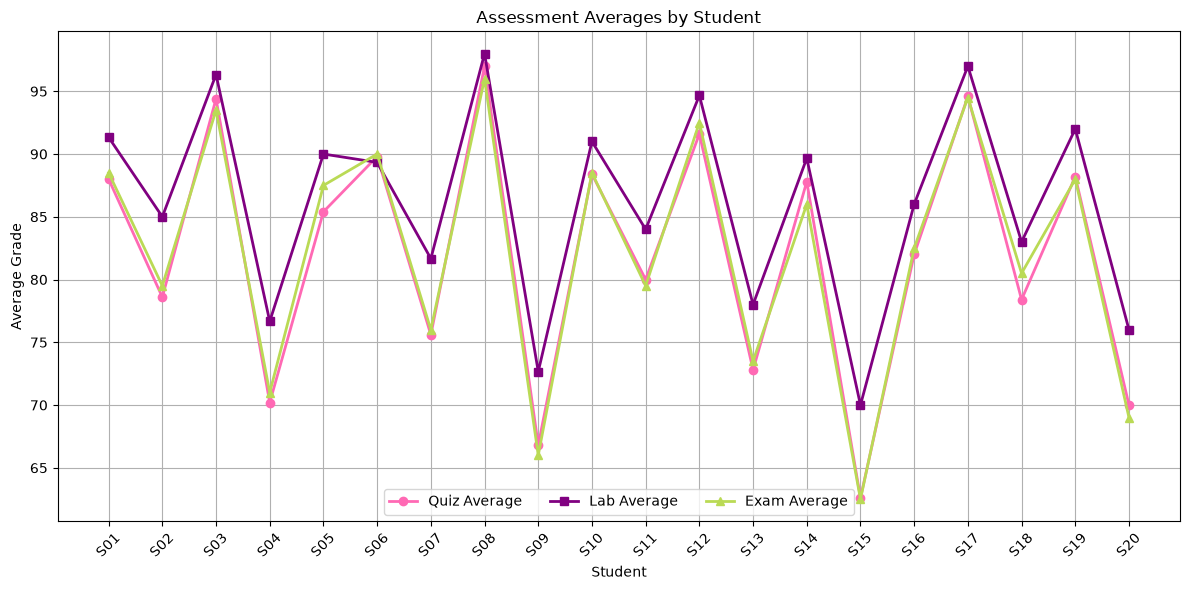

In [45]:
# x holds one position (0-19) for each student
x = np.arange(len(student_ids))
plt.figure(figsize=(12, 6))

# draw the lines using varying markers, colors, and labels for the legend
plt.plot(x, quiz_averages, marker='o', color = '#FF69B4', linewidth=2, label='Quiz Average')
plt.plot(x, lab_averages, marker='s', color = 'purple', linewidth=2, label='Lab Average')
plt.plot(x, exam_averages, marker='^', color = '#bada55', linewidth=2, label='Exam Average')

# axes labels and graph label
plt.xlabel('Student')
plt.ylabel('Average Grade')
plt.title('Assessment Averages by Student')

# replace the numeric x positions with Student IDs, rotated so all are readable::
plt.xticks(x, student_ids, rotation=45)

# add a legend and a grid, then fit everything neatly in the figure using tight_layout
plt.legend(loc='lower center', ncol=3)
plt.grid(True)
plt.tight_layout()
plt.show()

Task 7: Create the Scatter Graph
This cell uses Matplotlib to create a scatter graph of each student's exam average. The size of each circle is scaled from the exam average, and the color shows the same value through a colorbar.

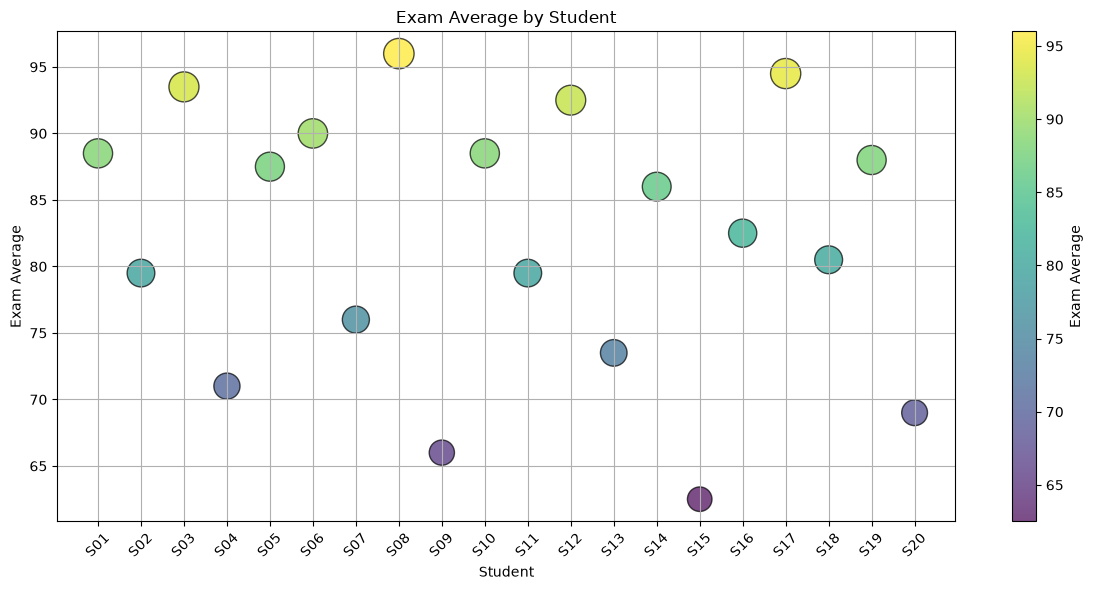

In [46]:
# scale the exam averages so the circle area grows with the exam average:

circle_sizes = exam_averages * 5
plt.figure(figsize=(12, 6))

# s sets the circle size and c sets the color from the same exam averages
plt.scatter(x, exam_averages, s=circle_sizes, c=exam_averages,
            cmap='viridis', alpha=0.7, edgecolors='black')

# label the axes, add a title, and show Student IDs along the x-axis
plt.xlabel('Student')
plt.ylabel('Exam Average')
plt.title('Exam Average by Student')
plt.xticks(x, student_ids, rotation=45)

# the colorbar explains what each color means, ledger
plt.colorbar(label='Exam Average')

# add a grid and fit the layout before showing the graph
plt.grid(True)
plt.tight_layout()
plt.show()

Task 8: Interpret the Results
This next cell will use NumPy functions to find the values to best answer these questions:
1.	Which assignment has the highest-class average?
2.	Which student has the highest overall row average?
3.	Which student has the lowest exam average?
4.	Do quiz, lab, and exam performances follow similar patterns? Identify one student who does not follow the general pattern.
5.	What does a larger circle represent in the scatter graph?


In [47]:
# assignment with the highest class average, essentially just finding the max in the column avgs.
best_col = np.argmax(column_averages)
print('This assignment had the highest class average:', assignment_names[best_col], 'with an average of',
      round(column_averages[best_col], 2))

# highest overall row average among the students, using max for student avgs
best_student = np.argmax(student_averages)
print('Highest overall student average:', student_ids[best_student], 'with an average of',
      round(student_averages[best_student], 2))

# lowest exam average among the students using min of exm avgs with associated student
low_exam = np.argmin(exam_averages)
print('Student with the lowest exam average:', student_ids[low_exam], 'with a score of', round(exam_averages[low_exam], 2))

#compare 
quiz_is_top = (quiz_averages > exam_averages) & (quiz_averages > lab_averages)
lab_is_top = (lab_averages > quiz_averages) & (lab_averages > exam_averages)
exam_is_top = (exam_averages > quiz_averages) & (exam_averages > lab_averages)
print('Number of students whose quiz average is highest:', np.sum(quiz_is_top), 'of', len(student_ids))
print('Number of students whose lab average is highest:', np.sum(lab_is_top), 'of', len(student_ids))
print('Number of students whose exam average is highest:', np.sum(exam_is_top), 'of', len(student_ids))

#this tells us, only one student's average isnt the highest in labs
# find student whose lab average is NOT labs
print("Student who's highest average isnt the lab:", [student_ids[i] for i in np.where(~lab_is_top)[0]])
i = student_ids.index('S06')
#stats of student
print('S06 -> quiz %.2f, lab %.2f, exam %.2f' %
      (quiz_averages[i], lab_averages[i], exam_averages[i]))

# correlation between the three category averages across students
print('Correlation matrix (quiz, lab, exam):')
print(np.round(np.corrcoef([quiz_averages, lab_averages, exam_averages]), 3))

This assignment had the highest class average: Lab 1 with an average of 86.9
Highest overall student average: S08 with an average of 97.1
Student with the lowest exam average: S15 with a score of 62.5
Number of students whose quiz average is highest: 0 of 20
Number of students whose lab average is highest: 19 of 20
Number of students whose exam average is highest: 1 of 20
Student who's highest average isnt the lab: ['S06']
S06 -> quiz 89.80, lab 89.33, exam 90.00
Correlation matrix (quiz, lab, exam):
[[1.    0.992 0.995]
 [0.992 1.    0.992]
 [0.995 0.992 1.   ]]


1.	Which assignment has the highest-class average?
    - Lab 1, with an average of 86.90
2.	Which student has the highest overall row average?
    - S08 with an average of 97.10
3.	Which student has the lowest exam average?
    - S15 w/ an exam average of 62.50
4.	Do quiz, lab, and exam performances follow similar patterns? Identify one student who does not follow the general pattern.
    - Mostly, yes. Students who score highly in one category tend to score high in the others (as the correlations are all above 0.98). That's why the line-graph looks cohesive. The lab line usually sits a few points above the quiz and exam lines. S06 does not follow this pattern: their lab average (89.33) is slightly below their quiz average (89.80) and exam average (90.00), while for the other 19 students the lab average is the highest of the three.
8.	What does a larger circle represent in the scatter graph?
    - A larger circle represents a higher exam average a the circle is scaled from each studen'ts exam average, so the biggest circles belong to the top exam performers and vice versa,